# 03 - Lever Comparison, Phase 2 (confirmation, 3 seeds)

Phase 1 (1 seed) flagged **RoPE, SwiGLU, Pre-LN** as the promising single-lever wins.
Here we re-run each - plus the **baseline** and a combined **modern block**
(RoPE + SwiGLU + Pre-LN + RMSNorm, i.e. a LLaMA-style decoder) - over **3 seeds**
and report **mean +/- std**. Only effects larger than the seed-to-seed noise are real.

Key question: does **stacking** the winners compound, or does RoPE alone capture most of it?


In [1]:
%matplotlib inline
import os, csv, time
import numpy as np
import matplotlib.pyplot as plt
from sweep_utils import train_config, vocab, device

print("device:", device, "| vocab:", vocab)


device: cuda | vocab: 65


In [2]:
PHASE2 = {
    "baseline":     {},
    "rope":         {"pos_encoding": "rope"},
    "swiglu":       {"activation": "swiglu"},
    "pre_ln":       {"norm_placement": "pre"},
    "modern_combo": {"pos_encoding": "rope", "activation": "swiglu",
                     "norm_placement": "pre", "norm_type": "rmsnorm"},
}
SEEDS = [0, 1, 2]
print(len(PHASE2), "configs x", len(SEEDS), "seeds =", len(PHASE2) * len(SEEDS), "runs")


5 configs x 3 seeds = 15 runs


In [3]:
# === PHASE 2: 3 seeds per config ===
os.makedirs("../results", exist_ok=True)
runs_csv = "../results/sweep_phase2_runs.csv"
with open(runs_csv, "w", newline="") as f:
    csv.writer(f).writerow(["config", "seed", "val_ppl", "val_loss", "sec"])

summary = {}
t0 = time.time()
for name, over in PHASE2.items():
    ppls = []
    for s in SEEDS:
        r = train_config(over, seed=s, max_iters=3000)
        ppls.append(r["val_ppl"])
        with open(runs_csv, "a", newline="") as f:
            csv.writer(f).writerow([name, s, f"{r['val_ppl']:.4f}", f"{r['val_loss']:.4f}", f"{r['sec']:.1f}"])
        print(f"  {name:13s} seed {s}: val_ppl {r['val_ppl']:.3f}  ({r['sec']:.0f}s)", flush=True)
    summary[name] = (float(np.mean(ppls)), float(np.std(ppls)), ppls)
    print(f"{name:13s} MEAN {summary[name][0]:.3f} +/- {summary[name][1]:.3f}", flush=True)
print(f"\nPHASE 2 DONE in {(time.time()-t0)/60:.1f} min")


  baseline      seed 0: val_ppl 5.367  (70s)


  baseline      seed 1: val_ppl 5.399  (70s)


  baseline      seed 2: val_ppl 5.446  (69s)


baseline      MEAN 5.404 +/- 0.032


  rope          seed 0: val_ppl 5.074  (84s)


  rope          seed 1: val_ppl 5.070  (83s)


... (11 outputs left out)

  modern_combo  seed 1: val_ppl 4.403  (105s)


  modern_combo  seed 2: val_ppl 4.337  (105s)


modern_combo  MEAN 4.373 +/- 0.027



PHASE 2 DONE in 20.1 min


config          mean ppl    std  vs baseline
--------------------------------------------
modern_combo       4.373  0.027      -19.08%
rope               5.040  0.046       -6.75%
swiglu             5.182  0.052       -4.12%
pre_ln             5.281  0.017       -2.28%
baseline           5.404  0.032       +0.00%


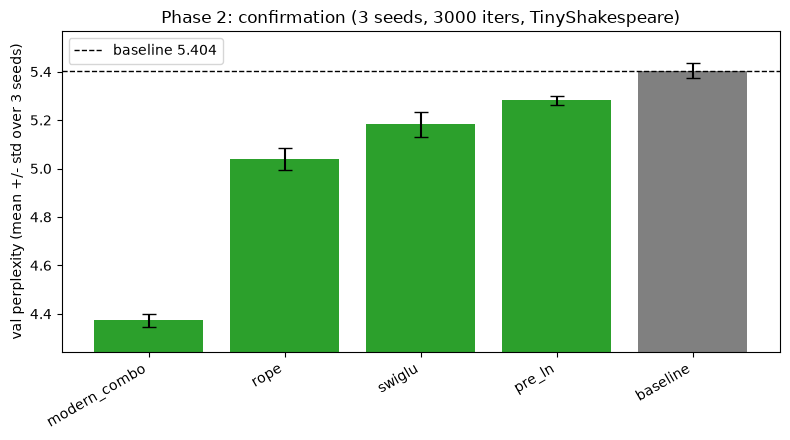

In [4]:
# summary table + chart with error bars
bmean = summary["baseline"][0]
order = sorted(summary.items(), key=lambda kv: kv[1][0])
print(f"{'config':14s} {'mean ppl':>9s} {'std':>6s} {'vs baseline':>12s}")
print("-" * 44)
for name, (m, sd, _) in order:
    print(f"{name:14s} {m:9.3f} {sd:6.3f} {100*(m-bmean)/bmean:+11.2f}%")

names = [n for n, _ in order]
means = [v[0] for _, v in order]
stds = [v[1] for _, v in order]
colors = ["gray" if n == "baseline" else ("tab:green" if v[0] < bmean else "tab:red")
          for n, v in order]
plt.figure(figsize=(8, 4.5))
plt.bar(names, means, yerr=stds, capsize=5, color=colors)
plt.axhline(bmean, ls="--", c="black", lw=1, label=f"baseline {bmean:.3f}")
plt.ylabel("val perplexity (mean +/- std over 3 seeds)")
plt.title("Phase 2: confirmation (3 seeds, 3000 iters, TinyShakespeare)")
plt.xticks(rotation=30, ha="right"); plt.legend()
plt.ylim(min(means) * 0.97, max(means) * 1.03)
plt.tight_layout(); plt.savefig("../results/sweep_phase2.png", dpi=120); plt.show()


## Reading this

A lever is a **real** win only if its mean is below the baseline by **more than the error bars**
(roughly, gap > 1-2x std). The `modern_combo` bar is the headline: if it clearly beats both the
baseline and the best single lever, "stacking compounds" is a clean result; if it only matches RoPE,
then RoPE dominates at this scale - also a finding worth reporting.
